# Eco-Concrete Strength Modeling (Notebook 1)

**Dataset:** UCI Concrete Compressive Strength Dataset

**Goal:** Rationalize the dataset to build a baseline concrete strength model for **compressive strength (MPa)** from concrete mixture compositions and **sustainability** (estimated CO₂ + cost proxies) to visualize tradeoffs.

> This notebook is designed to be a clean starting point for modeling.  
> It runs end-to-end once the dataset CSV is available locally.

---
## In this notebook:
1. Load + validate the dataset
2. Quick EDA + sanity checks
3. Train/test split with reproducible evaluation
4. Models:
    - Linear Regression (baseline)
    - Random Forest (nonlinear)
    - Gradient Boosting (strong general baseline)
5. Model evaluation metrics: **R²** and **MAE**
6. Simple **tradeoff plots**: predicted strength vs estimated CO₂ and “cost proxy”

---
## 0) Setup: establishing the dataset

The current dataset is from UCI Machine Learning Repository; however, versions of this dataset are available on Kaggle.

Kaggle datasets usually require either:
1) **Manual download** of the CSV from Kaggle (https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength), or  
2) Kaggle API (`kaggle datasets download ...`) after setting up an API token.

**Recommended for simplicity:**  
Download the dataset zip and extract the CSV into:
```
./data/
```
This notebook will look for a CSV file in `./data/` automatically.



In [1]:
# Installs dependencies when running in Google Colab.
# If these packages are already installed, this cell will finish quickly.
!pip -q install scikit-learn pandas numpy matplotlib

import os
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine learning tools
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GroupKFold,
    GroupShuffleSplit,
    cross_validate,
    GridSearchCV,
)
from sklearn.metrics import r2_score, mean_absolute_error, make_scorer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

# Ensures repeatability
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Output prefix keeps baseline results separate from future RCA results
OUTPUT_PREFIX = "baseline"

print("Setup complete.")


Setup complete.


## 1) Load the dataset

We’ll auto-detect the CSV in `./data/`. Ensure that the CSV is named "concrete_data.csv". The current UCI Concrete Compressive Strength dataset is one main CSV with the following columns:
- Supplementary Cementitious Materials (SCMs)
  - **Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer**
- Aggregates
  - **Coarse Aggregate, Fine Aggregate**, (varies based on material and source)
- Other Variables
  - **Age**
- Target Values
  - **Compressive Strength (MPa)**

All columns in the CSV can be divided into two categories: target and feature columns. Features refer to that affect target values, while targets refer to the mechanical/chemical properties. This notebook solely focuses on concrete compressive strength (a mechanical property) as its main target.
- Target
  - Compressive Strength (MPa)
- Features
  - Cement
  - Blast Furnace Slag
  - Fly Ash
  - Water
  - Superplasticizer
  - Coarse Aggregate
  - Fine Aggregate
  - Age

The notebook auto-detects for specifically these variables in datasets, be sure to check other datasets for additional variables. Possible variables to consider are permeability, tensile strength, and elasticity.

For local or drive options, you may add your dataset here:
```
./data/Concrete_Data.csv
```


In [3]:
# ============================================================
# Project configuration
# ============================================================
# Default: Repo, because that is the current workflow
# For drive execution later, comment the environment variable
os.environ["ECO_CONCRETE_RUN_MODE"] = "repo"
RUN_MODE = os.environ.get("ECO_CONCRETE_RUN_MODE", "drive").strip().lower()
EXPECTED_CSV = "concrete_data.csv"

# Mounts drive and establishes dataset
if RUN_MODE == "drive":
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError(
            "RUN_MODE='drive' requires Google Colab. "
            "Run this notebook in Colab or set ECO_CONCRETE_RUN_MODE=repo."
        ) from exc

    drive.mount("/content/drive")
    BASE_DIR = Path(
        os.environ.get(
            "ECO_CONCRETE_DRIVE_BASE",
            "/content/drive/MyDrive/ProjectName",
        )
    )

# Repo alternative: this makes the notebook runnable from GitHub later
elif RUN_MODE == "repo":
    cwd = Path.cwd()
    BASE_DIR = cwd.parent if cwd.name == "notebooks" else cwd

else:
    raise ValueError("RUN_MODE must be either 'drive' or 'repo'.")

# Output folders
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "figures"
OUT_DIR = BASE_DIR / "outputs"

DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

csv_path = DATA_DIR / EXPECTED_CSV
if not csv_path.exists():
    raise FileNotFoundError(
        f"Could not find the real baseline dataset at:\n{csv_path}\n\n"
        "Place concrete_data.csv in the project's data folder before continuing."
    )

# Loads CSV into dataframe
df = pd.read_csv(csv_path)

# Creates a backup of the raw dataset
df_raw = pd.read_csv(csv_path)

# Clean column-name spacing immediately.
df.columns = df.columns.str.strip()

# Displays set-up details for verification
print("RUN_MODE:", RUN_MODE)
print("BASE_DIR:", BASE_DIR)
print("Dataset:", csv_path)
print("Raw shape:", df_raw.shape)
df_raw.head()

RUN_MODE: repo
BASE_DIR: /content
Dataset: /content/data/concrete_data.csv
Raw shape: (1030, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 2) Clean column names + identify target

Different versions of the dataset sometimes have slightly different column names.
We’ll standardize the column names (lowercase, underscores), search for duplicates, ensure all the necessary columns are present, and check for realistic values

Most errors will require manual fixes or a different dataset.


In [4]:
# Normalizes the dataset to improve model speed and accuracy
def normalize_col(name: str) -> str:
    """Convert a column label to lowercase snake_case."""
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return re.sub(r"_+", "_", name).strip("_")

# Specifically searches for exact target and feature columns
def canonical_name(normalized: str) -> str:
    """Map known UCI column labels to a fixed baseline schema."""
    if "concrete_compressive_strength" in normalized or normalized.startswith("compressive_strength"):
        return "concrete_compressive_strength_mpa"
    if normalized.startswith("blast_furnace_slag"):
        return "blast_furnace_slag"
    if normalized.startswith("fly_ash"):
        return "fly_ash"
    if normalized.startswith("superplasticizer"):
        return "superplasticizer"
    if normalized.startswith("coarse_aggregate"):
        return "coarse_aggregate"
    if normalized.startswith("fine_aggregate"):
        return "fine_aggregate"
    if normalized.startswith("cement"):
        return "cement"
    if normalized.startswith("water"):
        return "water"
    if normalized.startswith("age"):
        return "age"
    return normalized

# Creates a backup, then cleans and standardizes the CSV columns for an expected format
df = df_raw.copy()
normalized = [normalize_col(c) for c in df.columns]
canonical = [canonical_name(c) for c in normalized]

# Checks for duplications during the standardization process
# If error occurs, lists the duplicates for fixing
if len(canonical) != len(set(canonical)):
    duplicates = pd.Series(canonical)[pd.Series(canonical).duplicated(keep=False)].tolist()
    raise ValueError(
        "Column normalization created duplicate names. "
        f"Resolve these columns manually: {duplicates}"
    )

# Renames all columns to the standardized canonical names
# Uses listed names as machine learning inputs
df.columns = canonical

BASELINE_FEATURES = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age",
]
MIX_COLUMNS = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
]

# Additional checks to ensure all the required columns are present in the CSV
TARGET_COL = "concrete_compressive_strength_mpa"
REQUIRED_COLUMNS = BASELINE_FEATURES + [TARGET_COL]

missing_columns = [c for c in REQUIRED_COLUMNS if c not in df.columns]
if missing_columns:
    raise KeyError(
        f"Missing required UCI columns: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}"
    )

for column in REQUIRED_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

missing_counts = df[REQUIRED_COLUMNS].isna().sum()
problem_columns = missing_counts[missing_counts > 0]
if not problem_columns.empty:
    raise ValueError(
        "Missing or nonnumeric values remain in required columns:\n"
        f"{problem_columns.to_string()}"
    )

# Checks for realistic values in the CSV columns
values = df[REQUIRED_COLUMNS].to_numpy(dtype=float)
if not np.isfinite(values).all():
    raise ValueError("The dataset contains nonfinite values in required columns.")

if (df[BASELINE_FEATURES] < 0).any().any():
    raise ValueError("One or more mixture features contain negative values.")

if (df["age"] <= 0).any() or (df[TARGET_COL] <= 0).any():
    raise ValueError("Age and compressive strength must be strictly positive.")

duplicate_rows = int(df.duplicated(subset=REQUIRED_COLUMNS).sum())
repeated_mix_rows = int(df.duplicated(subset=MIX_COLUMNS, keep=False).sum())

# Defines the columns into machine learning variables
X = df[BASELINE_FEATURES].copy()
y = df[TARGET_COL].copy()

print("Validated shape:", df.shape)
print("Exact duplicate rows:", duplicate_rows)
print("Rows belonging to repeated base mixture compositions:", repeated_mix_rows)
print("Features:", BASELINE_FEATURES)
df[REQUIRED_COLUMNS].describe().T

Validated shape: (1030, 9)
Exact duplicate rows: 25
Rows belonging to repeated base mixture compositions: 784
Features: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
blast_furnace_slag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
fly_ash,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
water,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
superplasticizer,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
coarse_aggregate,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
fine_aggregate,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
age,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
concrete_compressive_strength_mpa,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


## 3) EDA + final sanity checks

In this section, we're able to check for target distribution and obvious outliers. Final checks for the dataset are done here.


Numeric columns: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age', 'concrete_compressive_strength_mpa']
Non-numeric columns: []


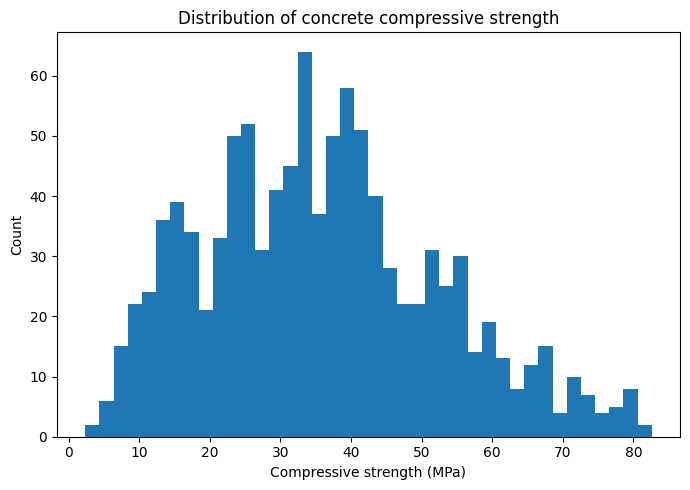

Saved: /content/figures/target_distribution_baseline.png


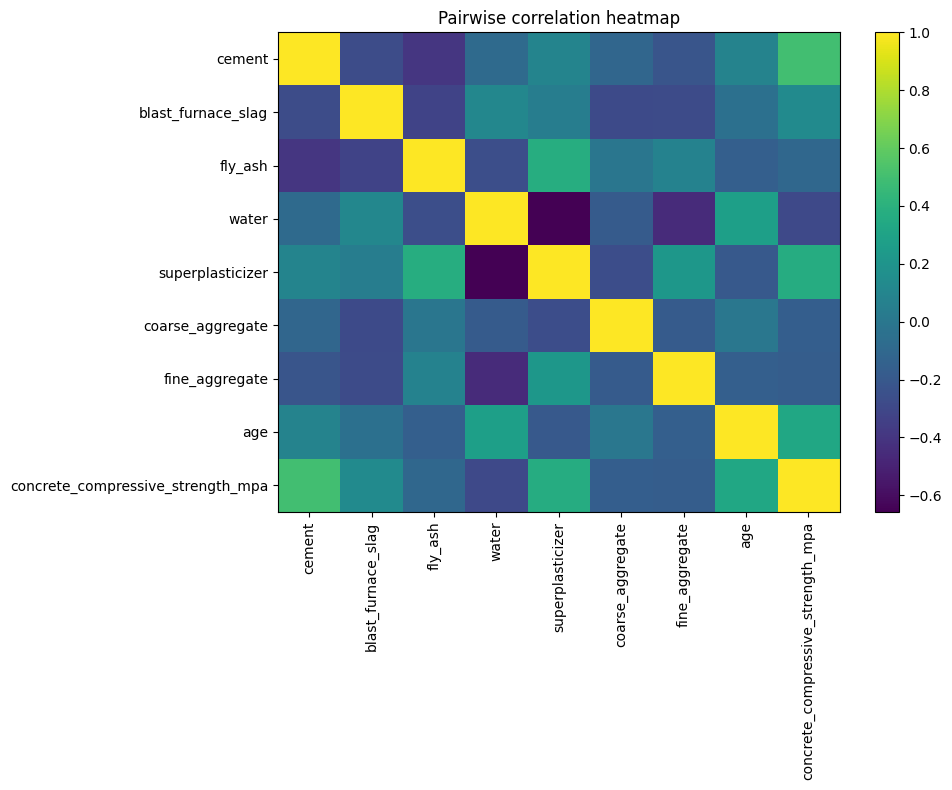

Saved: /content/figures/correlation_heatmap_baseline.png


In [5]:
# Final numeric columns check
# Prevents models from crashing during training
for c in df.columns:
    if c == TARGET_COL:
        continue
    # If a column is object but should be numeric, try coercion
    if df[c].dtype == "object":
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Drop rows where target is missing
# These rows can't be used to improve the model's performance
df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
print("Numeric columns:", numeric_cols)
print("Non-numeric columns:", [c for c in df.columns if c not in numeric_cols])

# Target distribution graph
    # Histogram graph shows how MPa varies and shows the mean/median
    # Can be used to improve clustering around a specific MPa
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(df[TARGET_COL], bins=40)
ax.set_xlabel("Compressive strength (MPa)")
ax.set_ylabel("Count")
ax.set_title("Distribution of concrete compressive strength")
fig.tight_layout()
hist_path = FIG_DIR / f"target_distribution_{OUTPUT_PREFIX}.png"
fig.savefig(hist_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", hist_path)

# Correlations heatmap (quick glance)
    # Correlation heatmap represents the relationship between materials
    # Yellow is positive correlation (increases together)
    # Purple is negative correlation (decreases together)
    # Graphical representation of feature improtance
corr = df[REQUIRED_COLUMNS].corr()
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, aspect="auto")
fig.colorbar(image, ax=ax)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
ax.set_title("Pairwise correlation heatmap")
fig.tight_layout()
corr_path = FIG_DIR / f"correlation_heatmap_{OUTPUT_PREFIX}.png"
fig.savefig(corr_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", corr_path)

**Target Distribution Histogram:**
The target distribution graph shows a few peaks around 20-40 MPa, but generally follows a skewed distribution. This means that the machine-learning models trained from this data will most likely be more accurate for concrete compressive strength between 0 and 40 MPa. Note that this graph does not automatically assume that the target follows a normal distribution.

**Correlation Heatmap:**
The purpose of this graph is to analyze the exploratory relationships between variables in the UCI dataset. The heatmap demonstrates that age, cement, and superplasticizer have a positive correlation with concrete compressive strength, showing they're useful when making concrete compressive strength predictions. Other features seem to have a lesser or negative correlation, indicating that these features are less useful in making strength predictions. However, it only provides exploratory context for the present data and should not be interpreted as causal evidence or as a replacement for model-based feature importance.

## 4) Holdout split and cross-validation design

Repeated base mixture compositions are kept together where possible so that the same recipe is not placed in both training and testing due to a difference in age.


In [6]:
# Build a group label from mixture composition, excluding age and strength.
# If the same base composition appears at multiple ages, all of its rows stay
# together in either training or testing.
mix_groups = pd.util.hash_pandas_object(
    df[MIX_COLUMNS], index=False
).astype(str)

# Checks for number of distinct groups, then chooses a split method
# Group shuffle split prevents test data memorization if applicable
# Otherwise, code uses standard train test split
if mix_groups.nunique() < len(df):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=RANDOM_STATE,
    )
    train_idx, test_idx = next(splitter.split(X, y, groups=mix_groups))
    split_method = "grouped holdout split"
else:
    indices = np.arange(len(df))
    train_idx, test_idx = train_test_split(
        indices,
        test_size=0.20,
        random_state=RANDOM_STATE,
    )
    split_method = "random row holdout split"

# Prevents modifications to the original dataset
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train = mix_groups.iloc[train_idx].copy()

# Checks for amount of groups and chooses a method
# GroupKFold prevents groups from being in both training and testing sets
# in 5 fold cross validation
# Otherwise use standard KFold with shuffling
if groups_train.nunique() >= 5 and groups_train.nunique() < len(groups_train):
    cv = GroupKFold(n_splits=5)
    cv_groups = groups_train
    cv_method = "5-fold GroupKFold"
else:
    cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_groups = None
    cv_method = "5-fold shuffled KFold"

print("Holdout method:", split_method)
print("Cross-validation method:", cv_method)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Holdout method: grouped holdout split
Cross-validation method: 5-fold GroupKFold
Train shape: (793, 8)
Test shape: (237, 8)


## 5) Untuned baseline model comparison w/ training set cross-validation

Model selection is based only on cross-validation performed within the training data. The held-out test set is reserved for final confirmation.

### Models
- **Linear Regression** (baseline; interpretable)
- **Random Forest** (handles nonlinear interactions well)
- **Gradient Boosting** (often a strong default for tabular regression)

We’ll evaluate with:
- **R²** (higher is better)
- **MAE** in MPa (lower is better)


In [7]:
def negative_mae_scorer():
    return make_scorer(mean_absolute_error, greater_is_better=False)

In [8]:
# Defines the baseline models for testing
baseline_models = {
    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "RandomForest": RandomForestRegressor(
        # Number of trees, improves quality of model prediction
        # Diminishing returns past 200 trees
        n_estimators=400,
        # Ensures repeatability
        random_state=RANDOM_STATE,
        # Determines memory consumption and training speed
        # "-1" -> utilizes all CPU cores available
        n_jobs=-1,
        # Minimum number of samples in final prediction of each tree
        # Prevents overfitting
        min_samples_leaf=1
    ),
    "GradientBoosting": GradientBoostingRegressor(
        # Ensures repeatability
        random_state=RANDOM_STATE,
    ),
}

# Runs cross-validation on training data as an initial test
# Higher "r2" value indicates how well the model fits training data
cv_rows = []
for name, model in baseline_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        groups=cv_groups,
        scoring={"r2": "r2", "mae": negative_mae_scorer()},
        return_train_score=False,
        n_jobs=1,
    )
    cv_rows.append({
        "model": name,
        "cv_r2_mean": float(np.mean(scores["test_r2"])),
        "cv_r2_std": float(np.std(scores["test_r2"], ddof=1)),
        "cv_mae_mean_mpa": float(-np.mean(scores["test_mae"])),
        "cv_mae_std_mpa": float(np.std(-scores["test_mae"], ddof=1)),
    })

# Stores results in the dataframe and ranks the models
# File is printed and saved for publication usage
cv_df = pd.DataFrame(cv_rows).sort_values(
    "cv_r2_mean", ascending=False
).reset_index(drop=True)

cv_path = OUT_DIR / f"baseline_model_comparison_cv_{OUTPUT_PREFIX}.csv"
cv_df.to_csv(cv_path, index=False)
print("Saved:", cv_path)
cv_df

Saved: /content/outputs/baseline_model_comparison_cv_baseline.csv


,model,cv_r2_mean,cv_r2_std,cv_mae_mean_mpa,cv_mae_std_mpa
0,GradientBoosting,0.843065,0.037257,4.796066,0.630029
1,RandomForest,0.836054,0.044353,4.684358,0.467065
2,LinearRegression,0.578600,0.068100,8.292083,0.740989


## 6. Evaluate all models on the held-out test set

The model is selected from training-set cross-validation for interpretation, not from the test-set ranking. The test set data is to determine the accuracy of each model on new, unseen data.

In [9]:
# Selects training-set model
selected_name = cv_df.iloc[0]["model"]
print("Model selected from training-set CV:", selected_name)

# Creates empty containers for storing data/models
test_rows = []
fitted_models = {}
test_predictions = {}

for name, model in baseline_models.items():
    # Prevents data leakage through cloning, then tests on untouched data
    fitted_model = clone(model).fit(X_train, y_train)
    pred = fitted_model.predict(X_test)

    # Saves all the results to the empty containers and checks the model
    # Calculates the r2 and MAE values
    fitted_models[name] = fitted_model
    test_predictions[name] = pred

    test_rows.append({
        "model": name,
        "selected_by_training_cv": name == selected_name,
        "test_r2": float(r2_score(y_test, pred)),
        "test_mae_mpa": float(mean_absolute_error(y_test, pred)),
    })

# Ranks the models by r2
test_df = pd.DataFrame(test_rows).sort_values(
    "test_r2", ascending=False
).reset_index(drop=True)

# Saves table for publication
test_path = OUT_DIR / f"baseline_model_test_results_{OUTPUT_PREFIX}.csv"
test_df.to_csv(test_path, index=False)
print("Saved:", test_path)
test_df

Model selected from training-set CV: GradientBoosting
Saved: /content/outputs/baseline_model_test_results_baseline.csv


,model,selected_by_training_cv,test_r2,test_mae_mpa
0,GradientBoosting,True,0.872233,4.861627
1,RandomForest,False,0.863395,4.890062
2,LinearRegression,False,0.618233,9.029970


## 7. Diagnostic figures for the model selected by training-set cross-validation

We’ll plot predicted vs actual for the best-performing model (by R²).


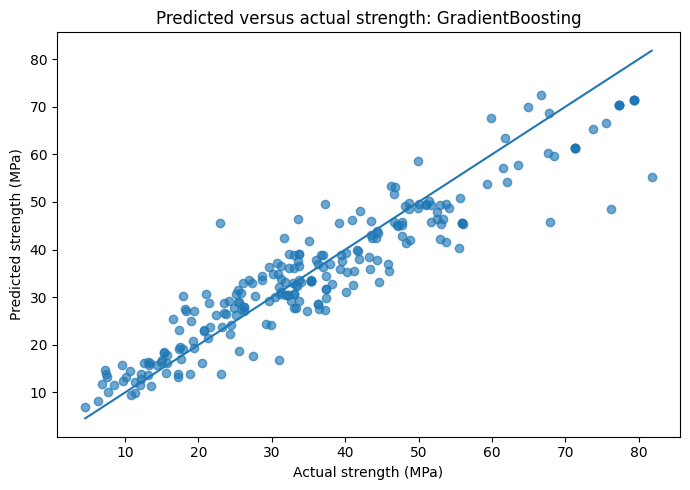

Saved: /content/figures/pred_vs_actual_GradientBoosting_baseline.png


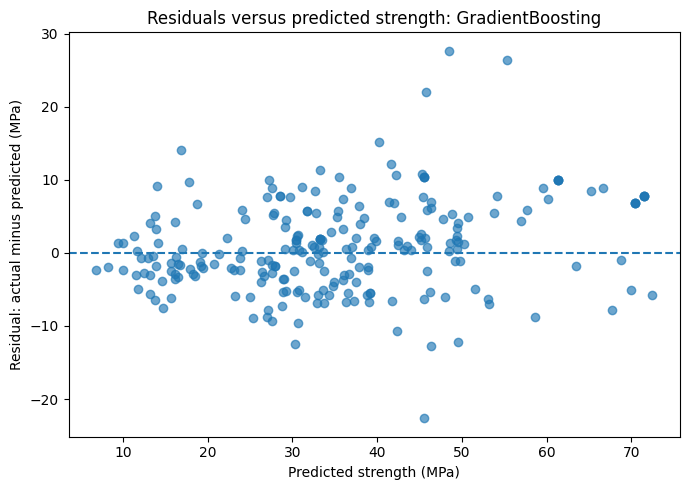

Saved: /content/figures/residual_plot_GradientBoosting_baseline.png


In [10]:
# Defines best model and calculates residuals for graphing
selected_model = fitted_models[selected_name]
selected_pred = test_predictions[selected_name]
residuals = y_test.to_numpy() - selected_pred

# Predicted vs. Actual Strength
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_test, selected_pred, alpha=0.65)
# Places 45-degree line
# Provides a visual aid to determine model accuracy
minimum = min(float(y_test.min()), float(selected_pred.min()))
maximum = max(float(y_test.max()), float(selected_pred.max()))
ax.plot([minimum, maximum], [minimum, maximum])
ax.set_xlabel("Actual strength (MPa)")
ax.set_ylabel("Predicted strength (MPa)")
ax.set_title(f"Predicted versus actual strength: {selected_name}")
fig.tight_layout()
pred_path = FIG_DIR / f"pred_vs_actual_{selected_name}_{OUTPUT_PREFIX}.png"
fig.savefig(pred_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", pred_path)

# Residuals graph (Negative = Overpredicted, Positive = Underpredicted)
# Provides another way to graph model accuracy
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(selected_pred, residuals, alpha=0.65)
ax.axhline(0, linestyle="--")
ax.set_xlabel("Predicted strength (MPa)")
ax.set_ylabel("Residual: actual minus predicted (MPa)")
ax.set_title(f"Residuals versus predicted strength: {selected_name}")
fig.tight_layout()

# Saves figure for publication
residual_path = FIG_DIR / f"residual_plot_{selected_name}_{OUTPUT_PREFIX}.png"
fig.savefig(residual_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", residual_path)

**Predicted vs Actual Scatterplot:** While inaccurate predictions and outliers exist, the Gradient Boosting model seems to cluster around the plotted line, indicating reasonable model prediction accuracy.

**Residual Distribution Scatterplot:** Model accuracy is shown to be accurate, with most predicted values hovering within 5 MPa of the actual value. The model seems underpredicts at a lesser magnitude more frequently; however, it also overpredicts more often at a higher magnitude greater than 5 MPa of the actual value.

## 8) Permutation importance

Permutation importance answers if shuffling a feature will degrade a model's performance. This is a good, model-agnostic way to interpret the trained model.


Saved: /content/outputs/permutation_importance_GradientBoosting_baseline.csv


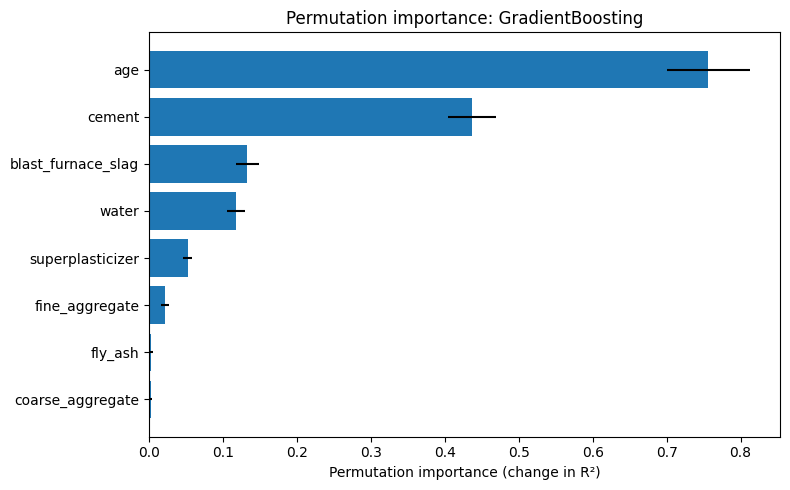

Saved: /content/figures/feature_importance_GradientBoosting_baseline.png


In [11]:
# Measures importance of each variable using "r2" as a scoring metric
perm = permutation_importance(
    selected_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="r2",
)

# Sorts variables and provides mean + STD for each
importance_df = pd.DataFrame({
    "feature": BASELINE_FEATURES,
    "importance_mean_delta_r2": perm.importances_mean,
    "importance_std_delta_r2": perm.importances_std,
}).sort_values("importance_mean_delta_r2", ascending=False)

# Saves table for publication
importance_path = OUT_DIR / f"permutation_importance_{selected_name}_{OUTPUT_PREFIX}.csv"
importance_df.to_csv(importance_path, index=False)
print("Saved:", importance_path)

# Number of variables considered
top_k = 8
# Takes variables and reverses the horizontal bar order for plotting
top = importance_df.head(top_k).iloc[::-1]
# Plots results of previous code
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    top["feature"],
    top["importance_mean_delta_r2"],
    xerr=top["importance_std_delta_r2"],
)
ax.set_xlabel("Permutation importance (change in R²)")
ax.set_title(f"Permutation importance: {selected_name}")
fig.tight_layout()
# Saves graph for publication
importance_fig_path = FIG_DIR / f"feature_importance_{selected_name}_{OUTPUT_PREFIX}.png"
fig.savefig(importance_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", importance_fig_path)

**Feature Importance Bar Graph:** The model depends on age, cement, and blast furnace slag when predicting concrete compressive strength. This does not indicate direct physical causation, just the model's dependence when making predictions. However, even though this graph matches real-world observations to an extent, it's also important to note that low-importance variables, such as fly ash, do not reflect their significance in practical applications. Additionally, correlated variables can distort the permutation importance values.